# Pregunta 1 — Análisis exploratorio

Antes de decidir nada sobre el modelo hay que contestar cinco preguntas
sobre los datos. Cada una condiciona una decisión posterior:

1. **¿Cuánta supervisión real hay?** — define si el problema es de
   arquitectura o de etiquetas.
2. **¿Cómo son los informes?** — define qué puede extraer un método de
   texto.
3. **¿Qué tan desbalanceadas están las doce etiquetas?** — entregable 6.
4. **¿El idioma cambia el resultado?** — entregable 7.
5. **¿Las etiquetas se parecen entre sí?** — si dos hallazgos van siempre
   juntos, doce sigmoides independientes es una suposición fuerte.

Todas las celdas **solo leen** disco. Ninguna entrena nada.

In [1]:
import collections
import csv
import json
import pathlib
import sys

import numpy as np
import matplotlib.pyplot as plt

# Raiz del proyecto en la maquina local. Orden: la variable REDES_RAIZ, la
# carpeta actual o alguna superior, y por ultimo la ruta fija de esta PC. Asi
# funciona en Jupyter/VS Code y en Colab conectado a un entorno de ejecucion
# local, aunque Jupyter se haya lanzado desde otra carpeta.
import os
RAIZ_LOCAL = pathlib.Path("D:/Backend/redesneuronales")
RAIZ = pathlib.Path(os.environ.get("REDES_RAIZ", pathlib.Path.cwd()))
while not (RAIZ / "pregunta1").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if not (RAIZ / "pregunta1").is_dir():
    RAIZ = RAIZ_LOCAL
if not (RAIZ / "pregunta1").is_dir():
    raise FileNotFoundError(
        f"No encuentro el proyecto (busque desde {pathlib.Path.cwd()} y en "
        f"{RAIZ_LOCAL}). En Colab: Conectar -> 'Conectar a un entorno de "
        "ejecucion local', o define REDES_RAIZ con la ruta del proyecto.")
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})


def leer_csv(ruta):
    # Acepta tanto una ruta absoluta (la que da rutas.py) como una relativa.
    p = pathlib.Path(ruta)
    if not p.is_absolute():
        p = RAIZ / p
    if not p.is_file():
        print(f"  (falta {ruta})")
        return []
    with p.open(encoding="utf-8") as f:
        return list(csv.DictReader(f))


# La ruta sale de pregunta1/rutas.py: prefiere pregunta1/datos/ (el
# enlace creado por alinear_datos.py) y cae a data_kaggle/ si no esta.
from pregunta1.rutas import TRAIN_CSV, describir
print(" ", describir())
TRAIN = leer_csv(TRAIN_CSV)
DEBILES = leer_csv("pregunta1/paso1_etiquetas_debiles/etiquetas_debiles.csv")
SELECCION = leer_csv("pregunta1/paso2_preprocesamiento/estudios_seleccionados.csv")

ETIQUETAS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
             "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
             "Contusion", "Fracture"]

print(f"train.csv        {len(TRAIN):>6,} filas")
print(f"etiquetas_debiles {len(DEBILES):>6,} filas")
print(f"seleccionados     {len(SELECCION):>6,} filas")

  datos de la Pregunta 1 en pregunta1/datos/
train.csv         4,407 filas
etiquetas_debiles  4,407 filas
seleccionados        573 filas


## 1. Cuánta supervisión real hay

Esta es la asimetría que define la pregunta entera.

estudios en train.csv        :  4,407
  con etiqueta de radiologo  :     58  (1.32%)
  con informe de texto       :  4,407  (100.0%)

  Por cada estudio etiquetado por un humano hay 75 sin etiquetar.
  Ahi esta todo el problema: la unica forma de usar el 98.7%
  restante es fabricarle etiquetas leyendo su informe, y eso
  introduce ruido que hay que MEDIR, no suponer.


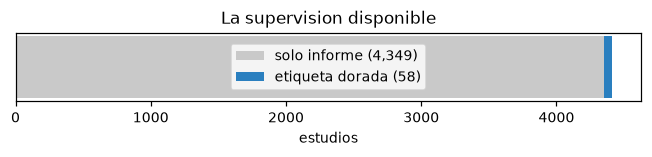

In [2]:
if TRAIN:
    con_oro = [r for r in TRAIN if any(r.get(e, "") not in ("", None)
                                       for e in ETIQUETAS)]
    con_texto = [r for r in TRAIN if (r.get("Report") or "").strip()]
    print(f"estudios en train.csv        : {len(TRAIN):>6,}")
    print(f"  con etiqueta de radiologo  : {len(con_oro):>6,}  "
          f"({100*len(con_oro)/len(TRAIN):.2f}%)")
    print(f"  con informe de texto       : {len(con_texto):>6,}  "
          f"({100*len(con_texto)/len(TRAIN):.1f}%)")
    print(f"\n  Por cada estudio etiquetado por un humano hay "
          f"{len(TRAIN)//max(1,len(con_oro))} sin etiquetar.")
    print("  Ahi esta todo el problema: la unica forma de usar el 98.7%")
    print("  restante es fabricarle etiquetas leyendo su informe, y eso")
    print("  introduce ruido que hay que MEDIR, no suponer.")

    fig, ax = plt.subplots(figsize=(6, 1.5))
    ax.barh([0], [len(TRAIN)-len(con_oro)], color="#c9c9c9",
            label=f"solo informe ({len(TRAIN)-len(con_oro):,})")
    ax.barh([0], [len(con_oro)], left=[len(TRAIN)-len(con_oro)],
            color="#2a7fbf", label=f"etiqueta dorada ({len(con_oro)})")
    ax.set_yticks([]); ax.set_xlabel("estudios"); ax.legend(loc="center")
    ax.set_title("La supervision disponible"); ax.grid(False)
    plt.tight_layout(); plt.show()

## 2. Cómo son los informes

Si el texto fuera uniforme, un método de reglas sería trivial. No lo es.

largo del informe (caracteres):
  mediana 977 | p10 288 | p90 2118 | max 4,743


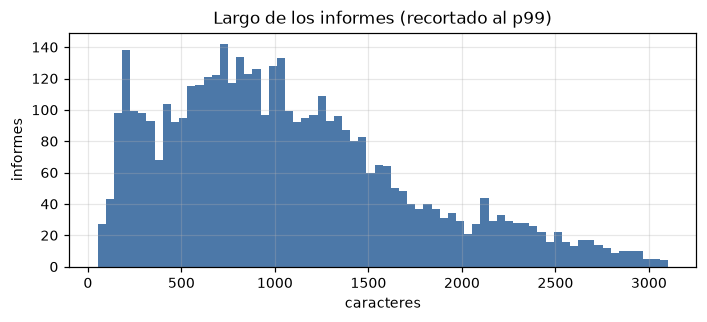


Tres informes al azar, para ver con que se trabaja:

  ... Central supporting system    - Anterior cruciate ligament (ACL): Normal.    - Posterior cruciate ligament (PCL): Normal.    - No evidence of anterior tibial translation is noted.       Medial compartment    - Medial meniscus: Pre...

  ...SOL DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Medial menisküs posterior hornunda evre 2 intrameniskal dejenerasyon ile uyumlu sinyal intensite değişiklikleri dikkati çekmiştir.Lateral menisküs normaldir. Med...

  ...SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs normaldir.Medial menisküs posterior hornu ve gövde kesimde grade II dejenerasyon izlenmektedir. Ön çapraz bağ ve arka çapraz bağ, lateral ve med...


In [3]:
if TRAIN:
    largos = [len((r.get("Report") or "")) for r in TRAIN
              if (r.get("Report") or "").strip()]
    largos = np.array(largos)
    print(f"largo del informe (caracteres):")
    print(f"  mediana {np.median(largos):.0f} | p10 {np.percentile(largos,10):.0f} "
          f"| p90 {np.percentile(largos,90):.0f} | max {largos.max():,}")

    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.hist(largos[largos < np.percentile(largos, 99)], bins=70,
            color="#4c78a8")
    ax.set_xlabel("caracteres"); ax.set_ylabel("informes")
    ax.set_title("Largo de los informes (recortado al p99)")
    plt.tight_layout(); plt.show()

    print("\nTres informes al azar, para ver con que se trabaja:")
    rng = np.random.default_rng(0)
    for r in rng.choice(TRAIN, 3, replace=False):
        t = (r.get("Report") or "").replace("\n", " ")[:230]
        print(f"\n  ...{t}...")

### La negación es el problema central

Contemos cuántas veces un informe nombra un hallazgo **para negarlo**. Si
esa fracción es alta, un buscador de palabras clave no solo es
imperfecto: es **sistemáticamente** erróneo.

In [4]:
import re

if TRAIN:
    NEG = re.compile(r"\b(no|without|negative for|absence of|unremarkable|"
                     r"rules? out|free of)\b", re.I)
    INC = re.compile(r"\b(possible|possibly|probable|suspected|may |"
                     r"cannot be excluded|questionable|equivocal)\b", re.I)
    n_neg = n_inc = n_tot = 0
    for r in TRAIN[:4000]:
        t = r.get("Report") or ""
        if not t.strip():
            continue
        n_tot += 1
        n_neg += bool(NEG.search(t))
        n_inc += bool(INC.search(t))
    print(f"sobre {n_tot:,} informes:")
    print(f"  contienen una NEGACION       : {n_neg:>6,} ({100*n_neg/n_tot:.1f}%)")
    print(f"  contienen una INCERTIDUMBRE  : {n_inc:>6,} ({100*n_inc/n_tot:.1f}%)")
    print("\n  Un buscador de palabras clave marcaria como POSITIVO a la")
    print("  mayoria de estos. Por eso el extractor necesita entender el")
    print("  estado de asercion, no solo la presencia del termino.")

sobre 4,000 informes:
  contienen una NEGACION       :  1,765 (44.1%)
  contienen una INCERTIDUMBRE  :    221 (5.5%)

  Un buscador de palabras clave marcaria como POSITIVO a la
  mayoria de estos. Por eso el extractor necesita entender el
  estado de asercion, no solo la presencia del termino.


## 3. El desbalance de las doce etiquetas (entregable 6)

etiqueta              positivos  prevalencia
----------------------------------------------
Medial Meniscus           2,010        45.6%
Effusion                  1,477        33.5%
Lateral Meniscus          1,160        26.3%
PF OA                     1,087        24.7%
Baker's                     764        17.3%
ACL                         739        16.8%
Contusion                   615        14.0%
MCL                         475        10.8%
Synovitis                   455        10.3%
Fracture                    348         7.9%
Medial OA                   329         7.5%
Lateral OA                  203         4.6%

  factor entre la mas comun y la mas rara: 9.9x


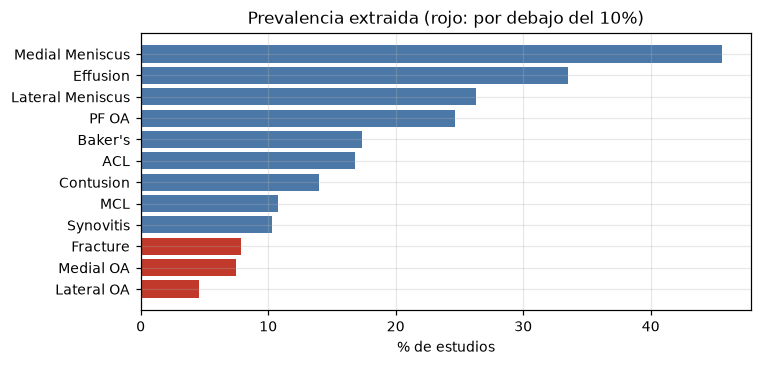

In [5]:
if DEBILES:
    META = {"StudyInstanceUID", "idioma", "traducido", "n_oraciones",
            "n_evidencias", "es_dorado", "veredicto"}
    ET = [c for c in DEBILES[0] if c not in META]
    cuentas = [(sum(1 for r in DEBILES if r[c] == "1"), c) for c in ET]
    cuentas.sort()
    print(f"{'etiqueta':<20} {'positivos':>10} {'prevalencia':>12}")
    print("-" * 46)
    for n, c in reversed(cuentas):
        print(f"{c:<20} {n:>10,} {100*n/len(DEBILES):>11.1f}%")
    print(f"\n  factor entre la mas comun y la mas rara: "
          f"{cuentas[-1][0]/max(1,cuentas[0][0]):.1f}x")

    fig, ax = plt.subplots(figsize=(7, 3.4))
    nom = [c for _, c in cuentas]
    val = [100*n/len(DEBILES) for n, _ in cuentas]
    ax.barh(nom, val, color=["#c0392b" if v < 10 else "#4c78a8" for v in val])
    ax.set_xlabel("% de estudios"); ax.set_title(
        "Prevalencia extraida (rojo: por debajo del 10%)")
    plt.tight_layout(); plt.show()

### Por qué el desbalance importa acá más que de costumbre

Con doce sigmoides independientes, cada etiqueta rara aporta poquísima
señal al gradiente. Y la métrica oficial es **AUC macro**: promedia las
doce por igual, así que una etiqueta con el 4% de prevalencia pesa lo
mismo que una con el 45%, pero se estima con una fracción del dato.

## 4. El idioma (entregable 7)

idioma    estudios       %  sin etiqueta        %
--------------------------------------------------
en           1,736   39.4%           200    11.5%
es             682   15.5%           129    18.9%
tr             546   12.4%           137    25.1%
hr             406    9.2%            38     9.4%
el             321    7.3%           174    54.2%
de             262    5.9%            70    26.7%
bg             220    5.0%            24    10.9%
nl             153    3.5%            27    17.6%
fr              81    1.8%             8     9.9%


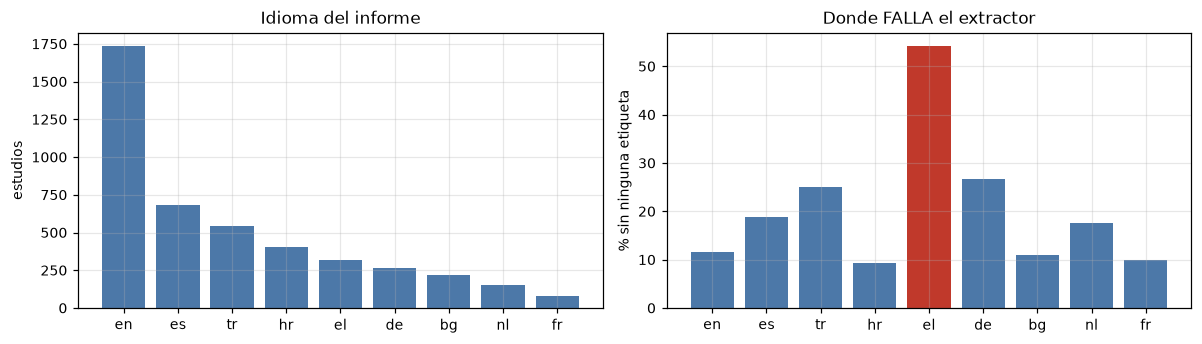


  El extractor deja sin etiqueta al 54.2% de los informes en 'el',
  contra el 11.5% en ingles: 4.7 veces mas.

  Eso no se ve en NINGUNA metrica agregada, y en un despliegue
  real significa que el sistema sirve peor en unos centros que
  en otros. Es exactamente el entregable 7.


In [6]:
if DEBILES:
    tot = collections.Counter(r["idioma"] for r in DEBILES)
    sin = [r for r in DEBILES if all(r[c] in ("0", "") for c in ET)]
    vac = collections.Counter(r["idioma"] for r in sin)
    print(f"{'idioma':<8} {'estudios':>9} {'%':>7} {'sin etiqueta':>13} {'%':>8}")
    print("-" * 50)
    for i, n in tot.most_common():
        print(f"{i:<8} {n:>9,} {100*n/len(DEBILES):>6.1f}% "
              f"{vac[i]:>13} {100*vac[i]/n:>7.1f}%")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    idiomas = [i for i, _ in tot.most_common()]
    axes[0].bar(idiomas, [tot[i] for i in idiomas], color="#4c78a8")
    axes[0].set_ylabel("estudios"); axes[0].set_title("Idioma del informe")
    tasas = [100*vac[i]/tot[i] for i in idiomas]
    axes[1].bar(idiomas, tasas,
                color=["#c0392b" if t > 30 else "#4c78a8" for t in tasas])
    axes[1].set_ylabel("% sin ninguna etiqueta")
    axes[1].set_title("Donde FALLA el extractor")
    plt.tight_layout(); plt.show()

    peor = max(idiomas, key=lambda i: vac[i]/tot[i])
    print(f"\n  El extractor deja sin etiqueta al {100*vac[peor]/tot[peor]:.1f}% "
          f"de los informes en '{peor}',")
    print(f"  contra el {100*vac['en']/tot['en']:.1f}% en ingles: "
          f"{(vac[peor]/tot[peor])/(vac['en']/tot['en']):.1f} veces mas.")
    print("\n  Eso no se ve en NINGUNA metrica agregada, y en un despliegue")
    print("  real significa que el sistema sirve peor en unos centros que")
    print("  en otros. Es exactamente el entregable 7.")

## 5. ¿Las doce etiquetas son independientes?

El modelo usa **doce sigmoides independientes**. Esa es una suposición: si
dos hallazgos aparecen casi siempre juntos, el modelo está gastando
capacidad en aprender dos veces lo mismo.

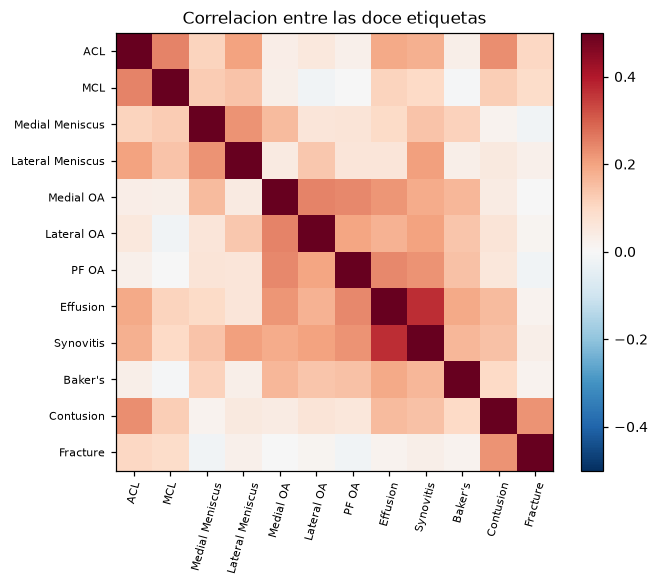

pares mas correlacionados:
  +0.369  Effusion <-> Synovitis
  +0.249  ACL <-> MCL
  +0.246  Medial OA <-> Lateral OA
  +0.242  PF OA <-> Effusion

pares mas ANTI-correlacionados:
  -0.019  PF OA <-> Fracture
  -0.018  Medial Meniscus <-> Fracture

  Las correlaciones son moderadas: ninguna pareja va siempre
  junta. Doce sigmoides independientes es una aproximacion
  razonable, aunque un modelo que las acople podria ganar algo.


In [7]:
if DEBILES:
    M = np.array([[1.0 if r[c] == "1" else 0.0 for c in ET]
                  for r in DEBILES])
    C = np.corrcoef(M.T)
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(C, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(len(ET))); ax.set_xticklabels(ET, rotation=75, fontsize=7)
    ax.set_yticks(range(len(ET))); ax.set_yticklabels(ET, fontsize=7)
    ax.set_title("Correlacion entre las doce etiquetas"); ax.grid(False)
    plt.colorbar(im, fraction=0.045); plt.tight_layout(); plt.show()

    pares = [(C[i, j], ET[i], ET[j])
             for i in range(len(ET)) for j in range(i+1, len(ET))]
    pares.sort()
    print("pares mas correlacionados:")
    for v, a, b in pares[-4:][::-1]:
        print(f"  {v:+.3f}  {a} <-> {b}")
    print("\npares mas ANTI-correlacionados:")
    for v, a, b in pares[:2]:
        print(f"  {v:+.3f}  {a} <-> {b}")
    print("\n  Las correlaciones son moderadas: ninguna pareja va siempre")
    print("  junta. Doce sigmoides independientes es una aproximacion")
    print("  razonable, aunque un modelo que las acople podria ganar algo.")

## 6. Qué ve el modelo: los tensores 2.5D

949 tensores en cache
  forma de uno: (8, 3, 224, 224)  float32
  rango: [0.000, 1.000]  media 0.168


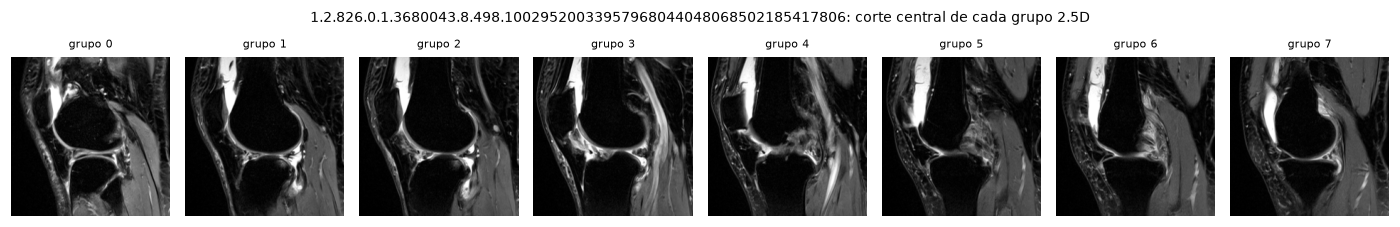

In [8]:
cache = RAIZ / "pregunta1/paso2_preprocesamiento/cache"
archivos = sorted(cache.glob("*.npy")) if cache.is_dir() else []
if archivos:
    x = np.load(archivos[0])
    print(f"{len(archivos)} tensores en cache")
    print(f"  forma de uno: {x.shape}  {x.dtype}")
    print(f"  rango: [{x.min():.3f}, {x.max():.3f}]  media {x.mean():.3f}")

    # 8 grupos de 3 cortes: se dibuja el corte central de cada grupo.
    v = x if x.ndim == 4 else x[None]
    n = min(8, v.shape[0])
    fig, axes = plt.subplots(1, n, figsize=(1.6*n, 2.1))
    for i in range(n):
        g = v[i]
        img = g[1] if g.ndim == 3 and g.shape[0] >= 3 else g.squeeze()
        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(f"grupo {i}", fontsize=7)
        axes[i].axis("off"); axes[i].grid(False)
    plt.suptitle(f"{archivos[0].stem}: corte central de cada grupo 2.5D",
                 fontsize=9)
    plt.tight_layout(); plt.show()

# Lo que este análisis deja decidido

| hallazgo | consecuencia |
|---|---|
| solo ~1.3% de los estudios tiene etiqueta humana | el trabajo es fabricar supervisión, y medir su ruido |
| la mayoría de los informes contiene una negación | un buscador de palabras clave es sistemáticamente erróneo, no solo imperfecto |
| las prevalencias van de ~5% a ~46% | el entregable 6 tiene materia; y el AUC macro pesa igual a etiquetas muy desiguales |
| el extractor falla casi 5× más en griego que en inglés | el entregable 7, y un sesgo que ninguna métrica agregada muestra |
| las etiquetas están moderadamente correlacionadas | doce sigmoides independientes es defendible |